In [39]:
import pandas as pd

from google.colab import files
uploaded = files.upload()

Saving KaggleV2-May-2016.csv to KaggleV2-May-2016 (1).csv


In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('KaggleV2-May-2016.csv')

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:
PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

Total missing values: 0


### Task 1: Missing Value Analysis

The dataset contains 110,527 records and 14 columns.

After checking all columns using `isnull().sum()`, no missing values were found.

The total number of missing values across the dataset is zero.

Therefore, no rows need to be dropped and no missing-value imputation is required.

However, the absence of missing values does not guarantee that all data is valid or consistent. Other data-quality issues, such as invalid values and outliers, still need to be investigated.

In [41]:
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = df[
    (df['Age'] < lower_bound) |
    (df['Age'] > upper_bound)
]

print("\nNumber of potential outliers:", len(outliers))
print("\nOutlier Age Values:")
print(outliers['Age'].value_counts().sort_index())

Q1: 18.0
Q3: 55.0
IQR: 37.0
Lower Bound: -37.5
Upper Bound: 110.5

Number of potential outliers: 5

Outlier Age Values:
Age
115    5
Name: count, dtype: int64


In [42]:
print("Records with Age = 115:")
print(df[df['Age'] == 115][
    ['PatientId', 'AppointmentID', 'Gender',
     'Age', 'Neighbourhood', 'No-show']
])

Records with Age = 115:
          PatientId  AppointmentID Gender  Age Neighbourhood No-show
63912  3.196321e+13        5700278      F  115    ANDORINHAS     Yes
63915  3.196321e+13        5700279      F  115    ANDORINHAS     Yes
68127  3.196321e+13        5562812      F  115    ANDORINHAS     Yes
76284  3.196321e+13        5744037      F  115    ANDORINHAS      No
97666  7.482346e+14        5717451      F  115      SÃO JOSÉ      No


In [43]:
print("Records with Age = -1:")
print(df[df['Age'] == -1])

Records with Age = -1:
          PatientId  AppointmentID Gender          ScheduledDay  \
99832  4.659432e+14        5775010      F  2016-06-06T08:58:13Z   

             AppointmentDay  Age Neighbourhood  Scholarship  Hipertension  \
99832  2016-06-06T00:00:00Z   -1         ROMÃO            0             0   

       Diabetes  Alcoholism  Handcap  SMS_received No-show  
99832         0           0        0             0      No  


In [44]:
valid_age_median = df.loc[df['Age'] >= 0, 'Age'].median()

print("Median of valid ages:", valid_age_median)

df.loc[df['Age'] == -1, 'Age'] = valid_age_median

print("\nRecords with invalid negative age:",
      (df['Age'] < 0).sum())

print("Records with age 115 retained:",
      (df['Age'] == 115).sum())

print("New minimum age:", df['Age'].min())

Median of valid ages: 37.0

Records with invalid negative age: 0
Records with age 115 retained: 5
New minimum age: 0


### Task 2: Outlier Detection and Investigation

The IQR method was used to identify potential outliers in the Age column.

Q1 was 18, Q3 was 55, and IQR was 37. The calculated lower and upper boundaries were -37.5 and 110.5 respectively.

Five records with an age of 115 were identified as potential outliers. After inspecting these records, they were retained because an age of 115 is possible and there was insufficient evidence to classify them as data-entry errors.

During further investigation, one record with an age of -1 was identified. This is an invalid value because a person's age cannot be negative.

The invalid age was replaced with the median age of valid records (37). The five records with age 115 were retained.

##Task 3

In [45]:
print("Before conversion:")
print(df[['ScheduledDay', 'AppointmentDay']].dtypes)

df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])

print("\nAfter conversion:")
print(df[['ScheduledDay', 'AppointmentDay']].dtypes)

Before conversion:
ScheduledDay      object
AppointmentDay    object
dtype: object

After conversion:
ScheduledDay      datetime64[ns, UTC]
AppointmentDay    datetime64[ns, UTC]
dtype: object


In [46]:
print(df[['ScheduledDay', 'AppointmentDay']].head())

print("\nDataset information:")
df.info()

               ScheduledDay            AppointmentDay
0 2016-04-29 18:38:08+00:00 2016-04-29 00:00:00+00:00
1 2016-04-29 16:08:27+00:00 2016-04-29 00:00:00+00:00
2 2016-04-29 16:19:04+00:00 2016-04-29 00:00:00+00:00
3 2016-04-29 17:29:31+00:00 2016-04-29 00:00:00+00:00
4 2016-04-29 16:07:23+00:00 2016-04-29 00:00:00+00:00

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype              
---  ------          --------------   -----              
 0   PatientId       110527 non-null  float64            
 1   AppointmentID   110527 non-null  int64              
 2   Gender          110527 non-null  object             
 3   ScheduledDay    110527 non-null  datetime64[ns, UTC]
 4   AppointmentDay  110527 non-null  datetime64[ns, UTC]
 5   Age             110527 non-null  int64              
 6   Neighbourhood   110527 non-null  object             
 7   Scholarship     

### Task 3: Fix Incorrect Data Types

The ScheduledDay and AppointmentDay columns represent dates but were previously identified as object columns during the initial dataset exploration.

Both columns were converted using pandas `pd.to_datetime()`.

After verification, both columns were confirmed as `datetime64[ns, UTC]`.

This allows date-based operations such as calculating waiting time, extracting weekdays and analysing appointment trends over time.

The remaining object columns (Gender, Neighbourhood and No-show) represent categorical data and were retained in their existing format.

##Task 4 – Create five charts

##Chart 1 – Histogram: Age distribution
A histogram groups numerical values into intervals called bins and shows how many observations fall into each interval.

**Question: What is the age distribution of patients in the medical appointment dataset?**


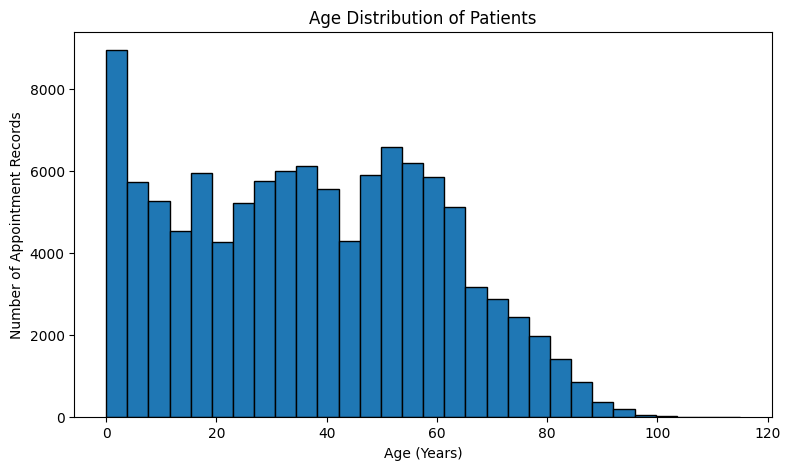

In [47]:
plt.figure(figsize=(9, 5))

plt.hist(df['Age'], bins=30, edgecolor='black')

plt.title('Age Distribution of Patients')
plt.xlabel('Age (Years)')
plt.ylabel('Number of Appointment Records')

plt.show()

**Question: What is the age distribution of patients in the medical appointment dataset?**

**Observations:**

- The 0–5 age group has the highest number of appointment records.
- A substantial number of appointments belong to adults between 20 and 60 years.
- The frequency of appointments decreases as age increases beyond 60.
- The distribution is right-skewed, with a longer tail towards older ages.
- Very few appointment records belong to individuals above 90 years.

**Conclusion:** The dataset contains appointment records across a wide range of ages, with particularly high representation among young children and adults.

##Chart 2 – Bar chart: Appointment attendance
**Question: How many appointments were attended versus missed?**


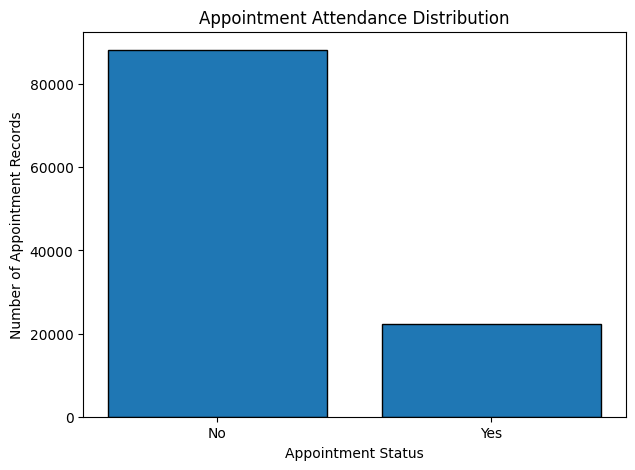

No-show
No     88208
Yes    22319
Name: count, dtype: int64


In [48]:
attendance_counts = df['No-show'].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    attendance_counts.index,
    attendance_counts.values,
    edgecolor='black'
)

plt.title('Appointment Attendance Distribution')
plt.xlabel('Appointment Status')
plt.ylabel('Number of Appointment Records')

plt.show()

print(attendance_counts)

**Question: How many appointments were attended versus missed?**

**Observations:**

- 88,208 appointment records (79.81%) were attended.
- 22,319 appointment records (20.19%) were missed.
- Attended appointments are significantly more frequent than missed appointments.
- The dataset contains an imbalance between the attendance categories.

**Conclusion:** Approximately one in five appointment records represents a missed appointment. This imbalance should be considered when building and evaluating a machine learning model for no-show prediction.

##Chart 3 – Scatter plot: Age vs waiting time

**Question: Does the time between scheduling and the appointment date vary with patient age?**

In [49]:
df['WaitingDays'] = (
    df['AppointmentDay'].dt.normalize() -
    df['ScheduledDay'].dt.normalize()
).dt.days

print("Corrected Waiting Time Statistics:")
print(df['WaitingDays'].describe())

print("\nNegative waiting-time records:",
      (df['WaitingDays'] < 0).sum())

print("\nSame-day appointments:",
      (df['WaitingDays'] == 0).sum())

Corrected Waiting Time Statistics:
count    110527.000000
mean         10.183702
std          15.254996
min          -6.000000
25%           0.000000
50%           4.000000
75%          15.000000
max         179.000000
Name: WaitingDays, dtype: float64

Negative waiting-time records: 5

Same-day appointments: 38563


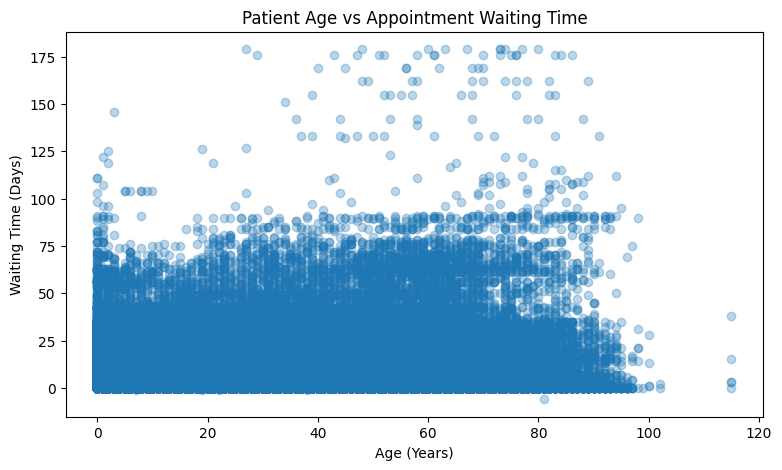

In [50]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df['Age'],
    df['WaitingDays'],
    alpha=0.3
)

plt.title('Patient Age vs Appointment Waiting Time')
plt.xlabel('Age (Years)')
plt.ylabel('Waiting Time (Days)')

plt.show()

In [51]:
negative_waiting = df[df['WaitingDays'] < 0]

print("Records with negative waiting time:")
print(negative_waiting[
    ['PatientId', 'AppointmentID',
     'ScheduledDay', 'AppointmentDay',
     'Age', 'WaitingDays']
])

Records with negative waiting time:
          PatientId  AppointmentID              ScheduledDay  \
27033  7.839273e+12        5679978 2016-05-10 10:51:53+00:00   
55226  7.896294e+12        5715660 2016-05-18 14:50:41+00:00   
64175  2.425226e+13        5664962 2016-05-05 13:43:58+00:00   
71533  9.982316e+14        5686628 2016-05-11 13:49:20+00:00   
72362  3.787482e+12        5655637 2016-05-04 06:50:57+00:00   

                 AppointmentDay  Age  WaitingDays  
27033 2016-05-09 00:00:00+00:00   38           -1  
55226 2016-05-17 00:00:00+00:00   19           -1  
64175 2016-05-04 00:00:00+00:00   22           -1  
71533 2016-05-05 00:00:00+00:00   81           -6  
72362 2016-05-03 00:00:00+00:00    7           -1  


In [52]:
invalid_count = (df['WaitingDays'] < 0).sum()

print("Invalid waiting-time records:", invalid_count)

df.loc[df['WaitingDays'] < 0, 'WaitingDays'] = np.nan

print("\nRemaining negative waiting times:",
      (df['WaitingDays'] < 0).sum())

print("Missing waiting-time values:",
      df['WaitingDays'].isna().sum())

print("\nUpdated statistics:")
print(df['WaitingDays'].describe())

Invalid waiting-time records: 5

Remaining negative waiting times: 0
Missing waiting-time values: 5

Updated statistics:
count    110522.000000
mean         10.184253
std          15.255115
min           0.000000
25%           0.000000
50%           4.000000
75%          15.000000
max         179.000000
Name: WaitingDays, dtype: float64


### Additional Data Quality Investigation – Waiting Time

Waiting time was calculated using the calendar dates of ScheduledDay and AppointmentDay.

Initially, five records were found to have negative waiting times.

After inspecting these records, it was observed that the appointment dates were earlier than their corresponding scheduling dates. Four records had a waiting time of -1 day, while one record had a waiting time of -6 days.

These values indicate inconsistencies in the recorded dates. Since the correct dates could not be determined, the five invalid waiting-time values were replaced with NaN in the derived WaitingDays column.

The original appointment records were retained to avoid unnecessarily losing other potentially useful information.

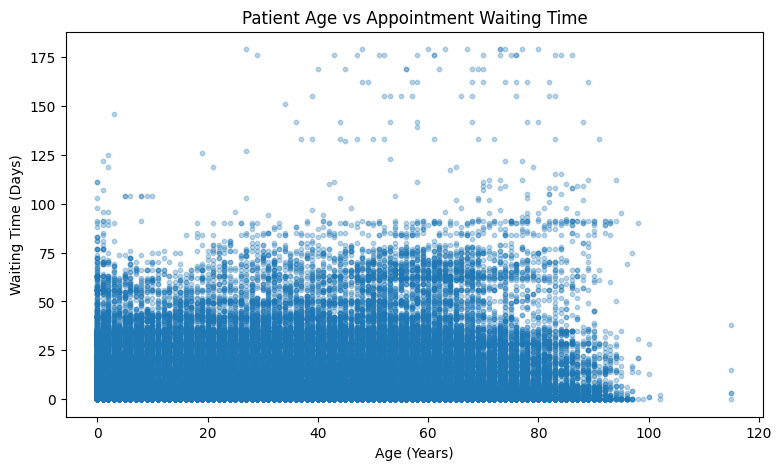

In [53]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df['Age'],
    df['WaitingDays'],
    alpha=0.3,
    s=10
)

plt.title('Patient Age vs Appointment Waiting Time')
plt.xlabel('Age (Years)')
plt.ylabel('Waiting Time (Days)')

plt.show()

**Question: Does appointment waiting time vary with patient age?**

**Observations:**

- Most appointment records have waiting times between 0 and 40 days.
- Waiting times vary across different age groups.
- No obvious strong linear relationship between age and waiting time is visible.
- A small number of appointments have exceptionally long waiting periods, reaching approximately 179 days.
- Many appointment records are concentrated around shorter waiting periods.

**Conclusion:** The scatter plot does not reveal an obvious strong linear relationship between patient age and appointment waiting time. Further statistical analysis would be required to investigate this relationship.

##Chart 4 – Line chart: Appointment trends over time

What is a line chart?
A line chart displays how a numerical value changes over an ordered variable, usually time.

For our analysis:
- X-axis: Appointment date.
- Y-axis: Number of appointments.

**Question: How does the number of appointments change over time?**

In [54]:
# Group appointment records by appointment date
daily_appointments = (
    df.groupby(df['AppointmentDay'].dt.date)
      .size()
)

print("Daily Appointment Counts:")
print(daily_appointments.head(10))

print("\nNumber of unique appointment dates:",
      len(daily_appointments))

Daily Appointment Counts:
AppointmentDay
2016-04-29    3235
2016-05-02    4376
2016-05-03    4256
2016-05-04    4168
2016-05-05    4273
2016-05-06    3879
2016-05-09    4520
2016-05-10    4308
2016-05-11    4474
2016-05-12    4394
dtype: int64

Number of unique appointment dates: 27


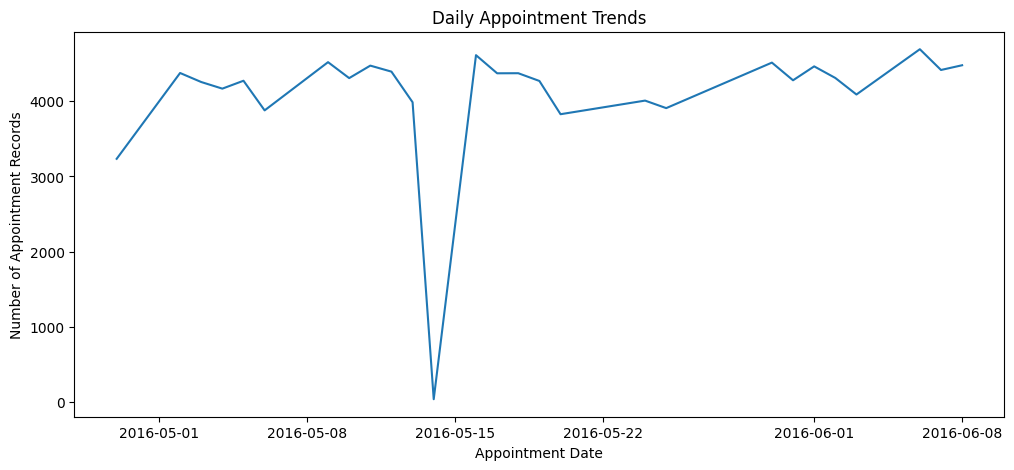

In [55]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_appointments.index,
    daily_appointments.values
)

plt.title('Daily Appointment Trends')
plt.xlabel('Appointment Date')
plt.ylabel('Number of Appointment Records')

plt.show()

In [56]:
print("Lowest appointment dates:")
print(daily_appointments.sort_values().head(10))

print("\nHighest appointment dates:")
print(daily_appointments.sort_values(ascending=False).head(10))

Lowest appointment dates:
AppointmentDay
2016-05-14      39
2016-04-29    3235
2016-05-20    3828
2016-05-06    3879
2016-05-25    3909
2016-05-13    3987
2016-05-24    4009
2016-06-03    4090
2016-05-04    4168
2016-05-03    4256
dtype: int64

Highest appointment dates:
AppointmentDay
2016-06-06    4692
2016-05-16    4613
2016-05-09    4520
2016-05-30    4514
2016-06-08    4479
2016-05-11    4474
2016-06-01    4464
2016-06-07    4416
2016-05-12    4394
2016-05-02    4376
dtype: int64


In [57]:
# Compare appointment volumes by day of the week
weekday_counts = (
    df.groupby(df['AppointmentDay'].dt.day_name())
      .size()
)

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_counts = weekday_counts.reindex(weekday_order)

print("Appointment records by weekday:")
print(weekday_counts)

Appointment records by weekday:
AppointmentDay
Monday       22715.0
Tuesday      25640.0
Wednesday    25867.0
Thursday     17247.0
Friday       19019.0
Saturday        39.0
Sunday           NaN
dtype: float64


In [58]:
may14_records = df[
    df['AppointmentDay'].dt.date ==
    pd.Timestamp('2016-05-14').date()
]

print("Records on May 14:", len(may14_records))
print("\nAttendance distribution:")
print(may14_records['No-show'].value_counts())

print("\nNeighbourhood distribution:")
print(may14_records['Neighbourhood'].value_counts())

Records on May 14: 39

Attendance distribution:
No-show
No     30
Yes     9
Name: count, dtype: int64

Neighbourhood distribution:
Neighbourhood
CARATOÍRA              30
ARIOVALDO FAVALESSA     5
SANTO ANTÔNIO           3
DO QUADRO               1
Name: count, dtype: int64


**Question: How does the number of appointments change over time?**

**Appointment trends:** Daily appointment volumes generally ranged between approximately 3,200 and 4,700 records. However, May 14, 2016, had only 39 appointment records, all from four neighbourhoods. The dataset contains only 39 Saturday appointments and no Sunday appointments. This suggests limited weekend appointment representation in the dataset, although the available dates are insufficient to establish a recurring weekend pattern.

**Conclusion:** The number of appointment records varies over time, with a noticeable dip around May 14. Further investigation is required to understand the reason for this unusual decline.

##Chart 5 – SMS reminders vs attendance

We'll use a grouped bar chart showing the attendance percentage for each SMS category.

In [59]:
# Group records by SMS status and attendance
sms_attendance = pd.crosstab(
    df['SMS_received'],
    df['No-show'],
    normalize='index'
) * 100

print("Attendance percentage by SMS status:")
print(sms_attendance)

Attendance percentage by SMS status:
No-show              No        Yes
SMS_received                      
0             83.296689  16.703311
1             72.425455  27.574545


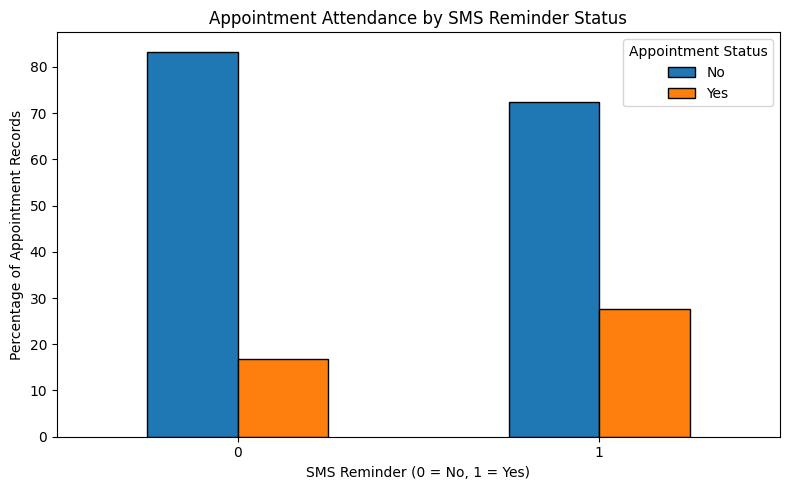

In [60]:
sms_attendance.plot(
    kind='bar',
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('Appointment Attendance by SMS Reminder Status')
plt.xlabel('SMS Reminder (0 = No, 1 = Yes)')
plt.ylabel('Percentage of Appointment Records')
plt.xticks(rotation=0)
plt.legend(title='Appointment Status')
plt.tight_layout()

plt.show()

**Question: Is appointment attendance different between patients who received SMS reminders and those who did not?**

**Observations:**

- Among appointment records without an SMS reminder, 83.30% were attended and 16.70% were missed.
- Among appointment records with an SMS reminder, 72.43% were attended and 27.57% were missed.
- The no-show rate was approximately 10.87 percentage points higher in the SMS-received group.
- This indicates an association between recorded SMS reminder status and appointment attendance.
- However, the observed difference does not establish that SMS reminders cause patients to miss appointments. Other factors, such as appointment waiting time, may influence the results.

**Conclusion:** Appointment records with SMS reminders have a higher observed no-show rate, but further investigation is needed to understand why this relationship exists.

### Task 5: Five Key Findings

1. **Age distribution:** Appointment records cover a wide range of ages, with a particularly high frequency among very young children and substantial representation among adults.

2. **Appointment attendance:** Of the 110,527 appointment records, 88,208 (79.81%) were attended, while 22,319 (20.19%) were missed.

3. **Waiting time:** The median waiting period was approximately 4 days, and 38,563 appointments were scheduled for the same calendar day. Five records contained inconsistent appointment and scheduling dates.

4. **Appointment trends:** Daily appointment volumes generally ranged between approximately 3,200 and 4,700 records. However, May 14, 2016, had only 39 appointment records, all from four neighbourhoods. The dataset contains only 39 Saturday appointments and no Sunday appointments. This suggests limited weekend appointment representation in the dataset, although the available dates are insufficient to establish a recurring weekend pattern.

5. **SMS reminders and attendance:** Appointment records with SMS reminders had a higher observed no-show rate (27.57%) than records without SMS reminders (16.70%). This is an association and does not establish causation.

### Ethics and Bias – Question 1

**Who is in this dataset, and who is missing from it?**

The dataset primarily represents people who booked medical appointments at the healthcare facilities included in the records. It contains information such as patient age, gender, neighbourhood, health indicators and appointment attendance status.

However, several groups may be missing or underrepresented:

- People who cannot afford healthcare due to financial difficulties.
- People who consult private or local doctors whose records are not included.
- People who rely on self-medication instead of visiting these healthcare facilities.
- People who choose not to seek medical attention.
- People who face geographical or transportation barriers to accessing healthcare.

Therefore, this dataset does not represent the entire population that requires healthcare. It represents only the patients who entered the appointment system, which creates a potential selection bias.

### Ethics and Bias – Question 2

**If a model trained on this dataset made decisions about real people, who could it treat unfairly?**

A machine learning model trained on this dataset could potentially treat certain groups of patients unfairly.

- **Elderly patients:** The model might incorrectly classify older patients as high-risk based on patterns in historical appointment records.
- **People from disadvantaged neighbourhoods:** Using neighbourhood as a predictive feature could introduce geographical or socioeconomic bias.
- **Patients with serious illnesses:** Patients who genuinely require medical attention could be deprioritised or denied appointments due to incorrect model predictions.
- **People with disabilities or chronic conditions:** Their individual circumstances and difficulties accessing healthcare may not be adequately represented in the dataset.

Therefore, predictions from a model should not be used as the sole basis for denying or prioritising healthcare appointments. Fairness, individual circumstances and potential consequences must be considered.

Ethics Question 3:

**is there anything in here that should not be used as a feature, even though it would help accuracy?**

I would avoid using PatientId and AppointmentID as input features because they are identifiers used to distinguish patient and appointment records rather than meaningful characteristics for predicting appointment attendance.

PatientId may be retained for linking multiple appointments belonging to the same patient, while AppointmentID may be retained for record tracking. However, these identifiers should be protected to maintain patient privacy.

Additionally, No-show should be used as the target variable rather than an input feature, as including it would cause target leakage.